In [1]:
import json
import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

In [2]:
# File/Folder Paths
# PROJECT_ROOT = Path(__file__).resolve().parents[1]
PROJECT_ROOT = Path.cwd().parents[0]
ANNOTATION_FILE = (PROJECT_ROOT/"data"/"SSDD"/"annotations"/"train.json")
IMAGE_DIR = (PROJECT_ROOT/"data"/"SSDD"/"images"/"train")

In [3]:
# Loading the annotations
with open(ANNOTATION_FILE, "r") as f:
    data = json.load(f)

images = data["images"]
annotations = data["annotations"]

In [7]:
# Mapping the images with annotations
import collections

annotations_by_image = collections.defaultdict(list)

for annotation in annotations:
    image_id = annotation["image_id"]
    annotations_by_image[image_id].append(annotation)

In [9]:
# Selecting random images   
random.seed(42)
selected_images = random.sample(images, 6)

Saved visualization to: /media/aryakumar/ACER/ARYAKUMAR-MISHRA/Projects/Machine-Learning/SAR_Anomaly_Detection/outputs/annotation_examples.png


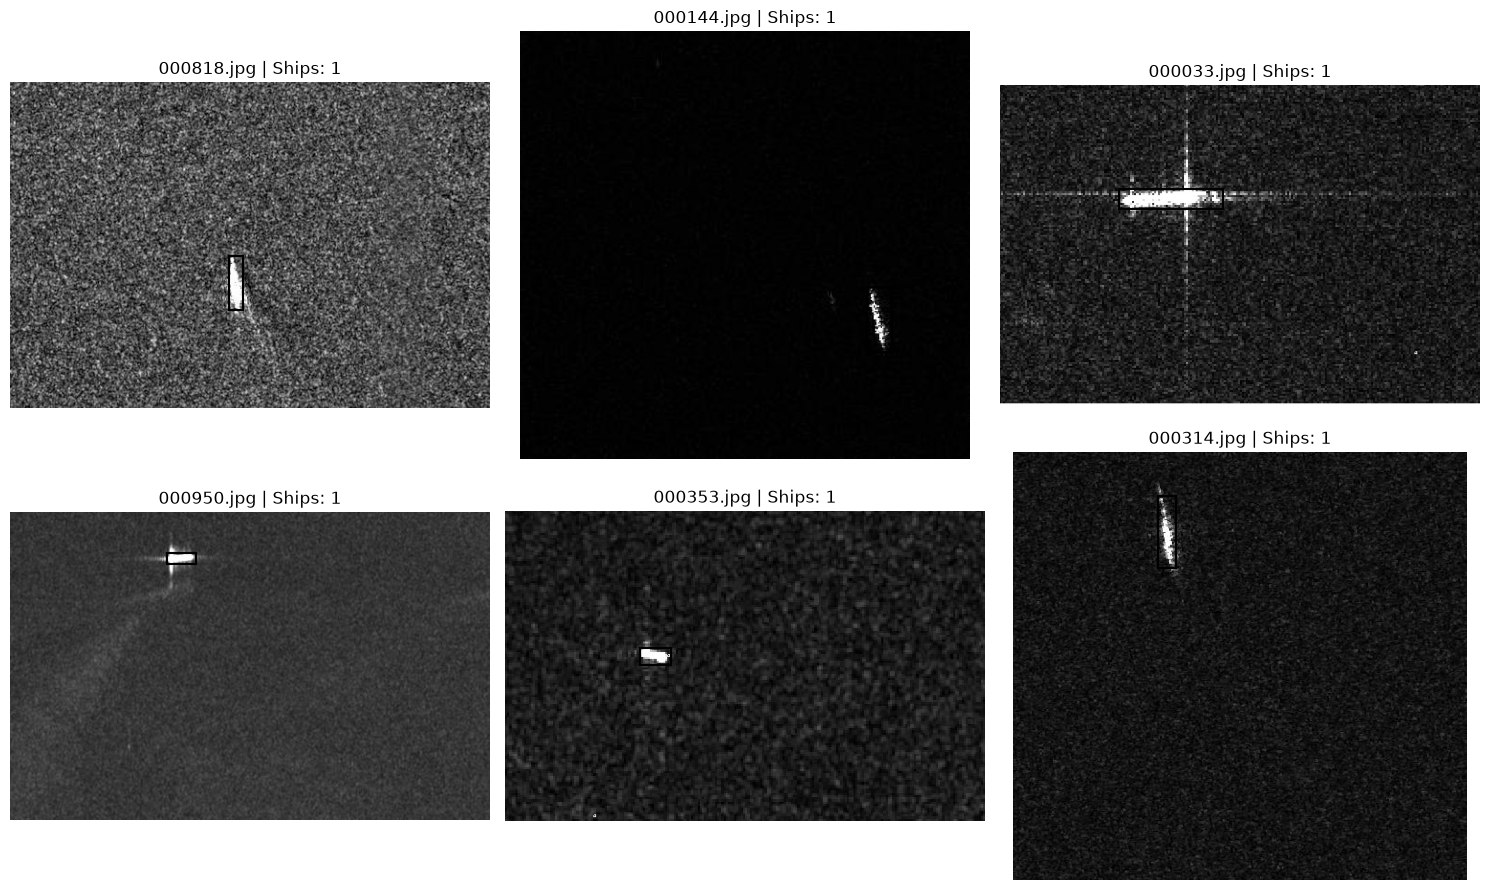

In [ ]:
# Plotting the images
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()


for ax, image_info in zip(axes, selected_images):
    image_id = image_info["id"]
    filename = image_info["file_name"]
    image_path = IMAGE_DIR / filename

    image = cv2.imread(str(image_path))

    if image is None:
        print(f"Could not load: {image_path}")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)

    image_annotations = annotations_by_image.get(image_id, [])

    for annotation in image_annotations:
        x, y, width, height = annotation["bbox"]
        rectangle = plt.Rectangle((x, y), width, height, fill=False, linewidth=1.5)
        ax.add_patch(rectangle)

    ax.set_title(f"{filename} | Ships: {len(image_annotations)}")

    ax.axis("off")


plt.tight_layout()

output_dir = PROJECT_ROOT / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "annotation_examples.png"

plt.savefig(output_path, dpi=150, bbox_inches="tight")

print(f"Saved visualization to: {output_path}")

plt.show()

In [11]:
annotation_filenames = {
    image["file_name"]
    for image in images
}

actual_filenames = {
    path.name
    for path in IMAGE_DIR.glob("*.jpg")
}

missing_from_json = actual_filenames - annotation_filenames

print("\nFiles not present in train.json")
print("-" * 60)

for filename in sorted(missing_from_json):
    print(filename)


Files not present in train.json
------------------------------------------------------------


In [12]:
missing_images = annotation_filenames - actual_filenames

print("\nImages referenced in JSON but missing from disk:")
for filename in sorted(missing_images):
    print(filename)


Images referenced in JSON but missing from disk:


In [16]:
from pathlib import Path
import json

IMAGE_DIR = Path("data/SSDD/images/train")
JSON_PATH = "../data/SSDD/annotations/train.json"

with open(JSON_PATH, "r") as f:
    data = json.load(f)

json_files = [img["file_name"] for img in data["images"]]
disk_files = [p.name for p in IMAGE_DIR.glob("*.jpg")]

print("JSON entries:", len(json_files))
print("Disk files  :", len(disk_files))

print("Unique JSON filenames:", len(set(json_files)))
print("Unique disk filenames:", len(set(disk_files)))

print("\nDuplicate filenames in JSON:")
for name in sorted(
    {x for x in json_files if json_files.count(x) > 1}
):
    print(name)

print("\nDuplicate filenames on disk:")
for name in sorted(
    {x for x in disk_files if disk_files.count(x) > 1}
):
    print(name)

print("\nDisk - JSON:")
print(sorted(set(disk_files) - set(json_files)))

print("\nJSON - Disk:")
print(sorted(set(json_files) - set(disk_files)))

JSON entries: 928
Disk files  : 0
Unique JSON filenames: 928
Unique disk filenames: 0

Duplicate filenames in JSON:

Duplicate filenames on disk:

Disk - JSON:
[]

JSON - Disk:
['000002.jpg', '000003.jpg', '000004.jpg', '000005.jpg', '000006.jpg', '000007.jpg', '000008.jpg', '000010.jpg', '000012.jpg', '000013.jpg', '000014.jpg', '000015.jpg', '000016.jpg', '000017.jpg', '000018.jpg', '000020.jpg', '000022.jpg', '000023.jpg', '000024.jpg', '000025.jpg', '000026.jpg', '000027.jpg', '000028.jpg', '000030.jpg', '000032.jpg', '000033.jpg', '000034.jpg', '000035.jpg', '000036.jpg', '000037.jpg', '000038.jpg', '000040.jpg', '000042.jpg', '000043.jpg', '000044.jpg', '000045.jpg', '000046.jpg', '000047.jpg', '000048.jpg', '000050.jpg', '000052.jpg', '000053.jpg', '000054.jpg', '000055.jpg', '000056.jpg', '000057.jpg', '000058.jpg', '000060.jpg', '000062.jpg', '000063.jpg', '000064.jpg', '000065.jpg', '000066.jpg', '000067.jpg', '000068.jpg', '000070.jpg', '000072.jpg', '000073.jpg', '000074.jp